# Approach comparison and final scores

Part of the approach series described in [`../APPROACHES.md`](../APPROACHES.md).

This notebook fits no model. It reads the standardized outputs of the four
approach notebooks and compares them:

| Key | Notebook | Action score | Rater parameters |
|---|---|---|---|
| `classical` | `02a_classical_consensus.ipynb` | raw mean (+ rater-centred mean) | naive severity, pairwise and leave-one-out consistency |
| `lmm` | `02b_linear_mixed_model.ipynb` | fair score μ + u (1–7 scale) | severity, drift |
| `mfrm` | `02c_ordinal_facet_model.ipynb` | latent θ (logits), expected rating | severity, infit/outfit |
| `jrt` | `02d_judge_response_theory.ipynb` | latent θ (N(0,1) scale) | severity, discrimination |

Run all four notebooks first. The comparison covers:
- agreement of action scores and ranks across approaches,
- agreement of rater parameters across approaches,
- a side-by-side reliability summary,
- exploratory rater flags,
- the final `action_scores.csv` / `rater_diagnostics.csv`,
- an automated cautious interpretation and the QC checklist.

## 0. Setup, reproducibility, and session information

In [1]:
import warnings
import platform
import subprocess
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

NOTEBOOK_KEY = "comparison"
SEED = 20260713
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Project paths (relative to the notebook folder "notebooks/")
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_MODELS = PROJECT_ROOT / "results" / "models"
RESULTS_LOGS = PROJECT_ROOT / "results" / "logs"

for d in [DATA_PROCESSED, RESULTS_TABLES, RESULTS_FIGURES, RESULTS_MODELS, RESULTS_LOGS]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

warnings.filterwarnings("default", category=UserWarning)

def save_fig(fig, name, caption=None):
    # Saves a figure as PNG and SVG under results/figures/.
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)
    print(f"Figure saved: {name}.png / {name}.svg")

def save_table(df_table, name, index=False):
    # Saves a table as CSV under results/tables/.
    path = RESULTS_TABLES / f"{name}.csv"
    df_table.to_csv(path, index=index)
    print(f"Table saved: {path.relative_to(PROJECT_ROOT)} "
          f"({df_table.shape[0]} rows x {df_table.shape[1]} columns)")
    return path

def save_diagnostics(values):
    # Scalar results (reliability, convergence, ...) for 03_approach_comparison.ipynb.
    out = pd.DataFrame({"quantity": list(values), "value": [float(v) for v in values.values()]})
    return save_table(out, f"model_diagnostics_{NOTEBOOK_KEY}")

WARNINGS_LOG = []
def log_warning(msg):
    # No silent failures: warnings are collected and exported at the end of the notebook.
    WARNINGS_LOG.append({"notebook": NOTEBOOK_KEY,
                         "timestamp": datetime.now(timezone.utc).isoformat(),
                         "message": msg})
    warnings.warn(msg)

print(f"Seed: {SEED}")
print(f"Project root: {PROJECT_ROOT}")

Seed: 20260713
Project root: /home/max/drive/projects/3_Creativity/11-paper-CAT-methodology/data-analysis/creativity-ratings-psychometrics


In [2]:
def get_git_hash():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
                             capture_output=True, text=True, timeout=5)
        if out.returncode == 0:
            return out.stdout.strip()
    except Exception:
        pass
    return "not available"

session_info = {
    "notebook": NOTEBOOK_KEY,
    "analysis_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "git_commit": get_git_hash(),
    "seed": SEED,
    "package_versions": {},
}
for pkg_name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'networkx']:
    try:
        mod = __import__(pkg_name)
        session_info["package_versions"][pkg_name] = getattr(mod, "__version__", "unknown")
    except ImportError:
        session_info["package_versions"][pkg_name] = "not installed"

with open(RESULTS_LOGS / f"session_info_{NOTEBOOK_KEY}.json", "w") as f:
    json.dump(session_info, f, indent=2)
print(json.dumps(session_info["package_versions"], indent=2))

{
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scipy": "1.18.0",
  "matplotlib": "3.11.0",
  "networkx": "3.6.1"
}


## 1. Data

Loads the cleaned ratings from `00_data_loading_preprocessing.ipynb`
(`data/processed/ratings_long_clean.csv`) and flags the largest connected
component of the rater–action graph. This block is identical in all approach
notebooks so that each notebook runs on its own.

In [3]:
CLEAN_PATH = DATA_PROCESSED / "ratings_long_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found. Run 00_data_loading_preprocessing.ipynb first.")

ratings_clean = pd.read_csv(CLEAN_PATH)
ratings_clean["action_id"] = ratings_clean["action_id"].astype(str)
ratings_clean["rater_id"] = ratings_clean["rater_id"].astype(str)

required_cols = ["action_id", "rater_id", "rating_numeric"]
missing_cols = [c for c in required_cols if c not in ratings_clean.columns]
if missing_cols:
    raise ValueError(f"Required variables missing from the preprocessed dataset: {missing_cols}")
assert ratings_clean["rating_numeric"].between(1, 7).all(), "Ratings outside 1-7!"
assert not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any(), "Duplicate (action_id, rater_id) rows!"

ratings_per_action = ratings_clean.groupby("action_id").size().rename("n_ratings")
n_raters = ratings_clean["rater_id"].nunique()
print(f"Loaded {len(ratings_clean)} ratings ({ratings_clean['action_id'].nunique()} actions, "
      f"{n_raters} raters).")
ratings_clean.head()

Loaded 7844 ratings (3669 actions, 22 raters).


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,urst3254,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,anma2416,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,anma2416,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,azne2115,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,urst3254,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


In [4]:
# Connected components of the bipartite rater-action graph. Rater severity is only
# identifiable within a component; full design diagnostics are in 01_data_overview.ipynb.
B = nx.Graph()
B.add_edges_from(zip(ratings_clean["action_id"], "R::" + ratings_clean["rater_id"]))
components = sorted(nx.connected_components(B), key=len, reverse=True)
n_components = len(components)

action_component_map = {n: i for i, comp in enumerate(components)
                        for n in comp if not str(n).startswith("R::")}
ratings_clean["connected_component"] = ratings_clean["action_id"].map(action_component_map)
ratings_clean["in_largest_component"] = ratings_clean["connected_component"] == 0
largest_component_actions = set(ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"])
largest_component_raters = set(ratings_clean.loc[ratings_clean["in_largest_component"], "rater_id"])

print(f"Connected components: {n_components}; largest: {len(largest_component_actions)} actions, "
      f"{len(largest_component_raters)} raters.")
if n_components > 1:
    log_warning(f"The rater-action graph has {n_components} components; rater-correcting "
                "models are estimated on the largest one only.")

Connected components: 1; largest: 3669 actions, 22 raters.


## 2. Load the approach results

Every approach notebook writes `scores_<key>.csv`, `raters_<key>.csv` and
`model_diagnostics_<key>.csv` to `results/tables/`. A missing file stops the
notebook with an instruction to run the corresponding notebook.

In [5]:
APPROACHES = {
    "classical": "02a_classical_consensus.ipynb",
    "lmm": "02b_linear_mixed_model.ipynb",
    "mfrm": "02c_ordinal_facet_model.ipynb",
    "jrt": "02d_judge_response_theory.ipynb",
}

def read_result(kind, key):
    path = RESULTS_TABLES / f"{kind}_{key}.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path.name} not found - run {APPROACHES[key]} first.")
    return pd.read_csv(path, dtype={"action_id": str, "rater_id": str})

scores = {k: read_result("scores", k) for k in APPROACHES}
raters = {k: read_result("raters", k) for k in APPROACHES}
diag = {k: dict(zip(d["quantity"], d["value"]))
        for k, d in ((k, read_result("model_diagnostics", k)) for k in APPROACHES)}

for k in APPROACHES:
    print(f"{k:10s}: {scores[k]['score'].notna().sum():5d} action scores, {len(raters[k]):3d} raters")

classical :  3669 action scores,  22 raters
lmm       :  3669 action scores,  22 raters
mfrm      :  3669 action scores,  22 raters
jrt       :  3669 action scores,  22 raters


## 3. Action scores across approaches

All scores are merged per action. They live on different scales (1–7 for the
raw mean and the LMM fair score; logits for MFRM θ; N(0,1) for JRT θ), so the
comparison uses Pearson and Spearman correlations, rank shifts and top/bottom
overlap rather than raw differences. Correlations use the actions that have a
score from every approach (the largest connected component).

In [6]:
c = scores["classical"]
score_comparison = c[["action_id", "n_ratings", "connected_component", "raw_mean", "raw_median",
                      "raw_se", "rater_centered_mean"]].copy()
score_comparison = score_comparison.merge(
    scores["lmm"][["action_id", "score", "score_se", "score_lower", "score_upper"]].rename(columns={
        "score": "lmm_score", "score_se": "lmm_score_se",
        "score_lower": "lmm_score_lower", "score_upper": "lmm_score_upper"}),
    on="action_id", how="left")
score_comparison = score_comparison.merge(
    scores["mfrm"][["action_id", "score", "score_se", "score_lower", "score_upper", "expected_rating"]].rename(columns={
        "score": "mfrm_theta", "score_se": "mfrm_theta_se", "score_lower": "mfrm_theta_lower",
        "score_upper": "mfrm_theta_upper", "expected_rating": "mfrm_expected_rating"}),
    on="action_id", how="left")
score_comparison = score_comparison.merge(
    scores["jrt"][["action_id", "score", "score_se", "score_lower", "score_upper"]].rename(columns={
        "score": "jrt_theta", "score_se": "jrt_theta_se",
        "score_lower": "jrt_theta_lower", "score_upper": "jrt_theta_upper"}),
    on="action_id", how="left")

score_cols = ["raw_mean", "rater_centered_mean", "lmm_score", "mfrm_theta", "jrt_theta"]
complete = score_comparison.dropna(subset=score_cols)
corr_pearson = complete[score_cols].corr(method="pearson")
corr_spearman = complete[score_cols].corr(method="spearman")
save_table(corr_pearson.reset_index().rename(columns={"index": "score"}), "comparison_score_corr_pearson")
save_table(corr_spearman.reset_index().rename(columns={"index": "score"}), "comparison_score_corr_spearman")
print(f"Actions with scores from all approaches: {len(complete)}")
print("\nSpearman correlations:")
print(corr_spearman.round(3))

Table saved: results/tables/comparison_score_corr_pearson.csv (5 rows x 6 columns)


Table saved: results/tables/comparison_score_corr_spearman.csv (5 rows x 6 columns)
Actions with scores from all approaches: 3669

Spearman correlations:
                     raw_mean  rater_centered_mean  lmm_score  mfrm_theta  \
raw_mean                1.000                0.959      0.952       0.954   
rater_centered_mean     0.959                1.000      0.992       0.986   
lmm_score               0.952                0.992      1.000       0.992   
mfrm_theta              0.954                0.986      0.992       1.000   
jrt_theta               0.946                0.974      0.983       0.992   

                     jrt_theta  
raw_mean                 0.946  
rater_centered_mean      0.974  
lmm_score                0.983  
mfrm_theta               0.992  
jrt_theta                1.000  


### 3.1 Rank shift and top/bottom overlap relative to the raw mean

How much does each rater-correcting approach change *which* actions count as
most and least creative, compared with the classical CAT average?

In [7]:
def top_bottom_overlap(df_, col_a, col_b, frac):
    n_top = max(1, int(len(df_) * frac))
    top_a, top_b = set(df_.nlargest(n_top, col_a)["action_id"]), set(df_.nlargest(n_top, col_b)["action_id"])
    bot_a, bot_b = set(df_.nsmallest(n_top, col_a)["action_id"]), set(df_.nsmallest(n_top, col_b)["action_id"])
    return len(top_a & top_b) / n_top, len(bot_a & bot_b) / n_top

shift_rows = []
for col in ["rater_centered_mean", "lmm_score", "mfrm_theta", "jrt_theta"]:
    rank_raw = complete["raw_mean"].rank()
    rank_other = complete[col].rank()
    row = {"compared_with_raw_mean": col,
           "spearman": complete["raw_mean"].corr(complete[col], method="spearman"),
           "mean_abs_rank_shift": (rank_raw - rank_other).abs().mean(),
           "n_actions": len(complete)}
    for frac in [0.05, 0.10]:
        top, bot = top_bottom_overlap(complete, "raw_mean", col, frac)
        row[f"top_{int(frac*100)}pct_overlap"] = top
        row[f"bottom_{int(frac*100)}pct_overlap"] = bot
    shift_rows.append(row)
rank_shift_df = pd.DataFrame(shift_rows)
save_table(rank_shift_df, "comparison_rank_shift")
rank_shift_df.round(3)

Table saved: results/tables/comparison_rank_shift.csv (4 rows x 8 columns)


,compared_with_raw_mean,spearman,mean_abs_rank_shift,n_actions,top_5pct_overlap,bottom_5pct_overlap,top_10pct_overlap,bottom_10pct_overlap
0,rater_centered_mean,0.959,220.822,3669,0.814,0.350,0.902,0.604
1,lmm_score,0.952,240.511,3669,0.716,0.219,0.776,0.519
2,mfrm_theta,0.954,243.061,3669,0.667,0.306,0.724,0.568
3,jrt_theta,0.946,262.414,3669,0.656,0.290,0.710,0.538


Figure saved: fig_comparison_action_scores.png / fig_comparison_action_scores.svg


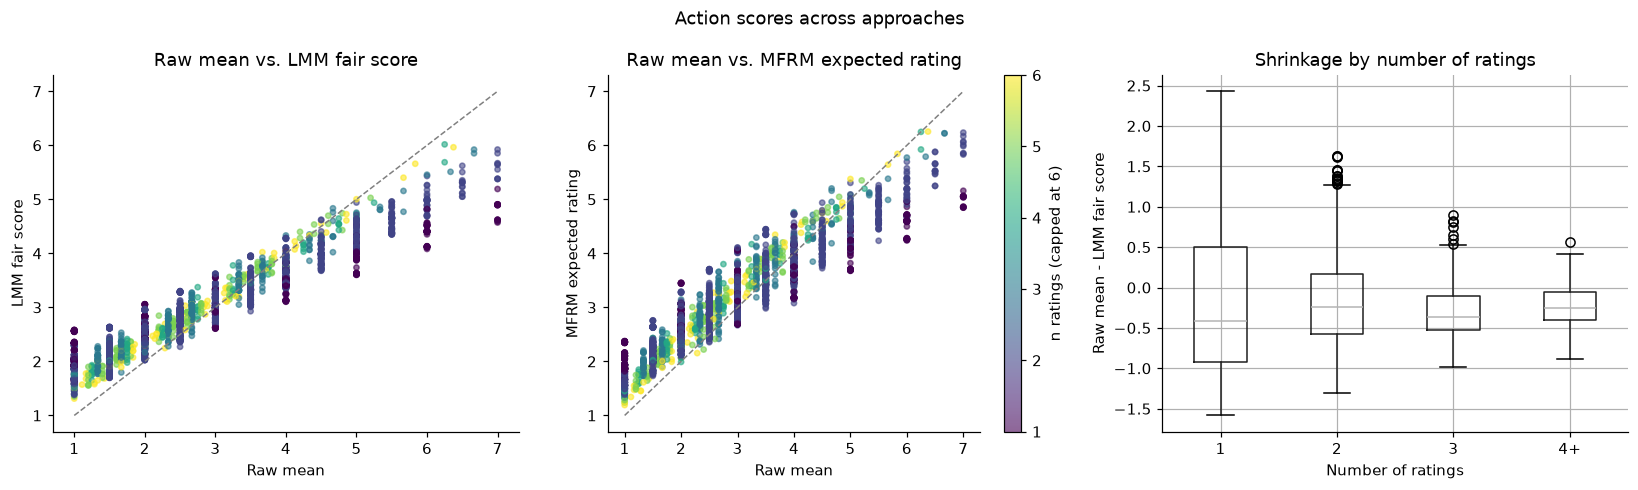

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, label) in zip(axes[:2], [("lmm_score", "LMM fair score"),
                                       ("mfrm_expected_rating", "MFRM expected rating")]):
    sc = ax.scatter(score_comparison["raw_mean"], score_comparison[col],
                    c=score_comparison["n_ratings"].clip(upper=6), cmap="viridis", s=12, alpha=0.6)
    ax.plot([1, 7], [1, 7], color="grey", ls="--", lw=1)
    ax.set_xlabel("Raw mean")
    ax.set_ylabel(label)
    ax.set_title(f"Raw mean vs. {label}")
fig.colorbar(sc, ax=axes[1], label="n ratings (capped at 6)")

score_comparison["n_ratings_bin"] = pd.cut(score_comparison["n_ratings"], [0, 1, 2, 3, np.inf],
                                           labels=["1", "2", "3", "4+"])
score_comparison["diff_raw_lmm"] = score_comparison["raw_mean"] - score_comparison["lmm_score"]
score_comparison.boxplot(column="diff_raw_lmm", by="n_ratings_bin", ax=axes[2])
axes[2].set_xlabel("Number of ratings")
axes[2].set_ylabel("Raw mean - LMM fair score")
axes[2].set_title("Shrinkage by number of ratings")
fig.suptitle("Action scores across approaches")
fig.tight_layout()
save_fig(fig, "fig_comparison_action_scores",
         "Raw mean vs. LMM fair score (left) and vs. the MFRM expected rating (middle), coloured "
         "by number of ratings; right: raw mean minus LMM fair score by number of ratings, "
         "showing stronger shrinkage for actions with few ratings.")
plt.show()

## 4. Rater parameters across approaches

**Severity.** All four approaches estimate a rater shift (classical: the naive
rater mean deviation). The values are on different scales, so we compare them
by correlation.

**Rater quality.** Four indicators from different traditions:
- leave-one-out consistency (classical, `02a`),
- mean pairwise weighted kappa (classical, `02a`),
- infit/outfit (MFRM, `02c`),
- discrimination (JRT, `02d`).

Convergent indicators make a rater-quality judgement more robust than any
single index. Note that higher fit mean squares mean *more* noise.

Table saved: results/tables/comparison_rater_severity_corr.csv (4 rows x 5 columns)
Table saved: results/tables/comparison_rater_quality_corr.csv (5 rows x 6 columns)
Spearman correlations of rater severity:
                    severity_classical  severity_lmm  severity_mfrm  \
severity_classical               1.000         0.965          0.975   
severity_lmm                     0.965         1.000          0.993   
severity_mfrm                    0.975         0.993          1.000   
severity_jrt                     0.969         0.980          0.991   

                    severity_jrt  
severity_classical         0.969  
severity_lmm               0.980  
severity_mfrm              0.991  
severity_jrt               1.000  

Spearman correlations of rater-quality indicators:
                              leave_one_out_spearman  \
leave_one_out_spearman                         1.000   
mean_pairwise_weighted_kappa                   0.444   
infit_mnsq                               

Figure saved: fig_comparison_rater_parameters.png / fig_comparison_rater_parameters.svg


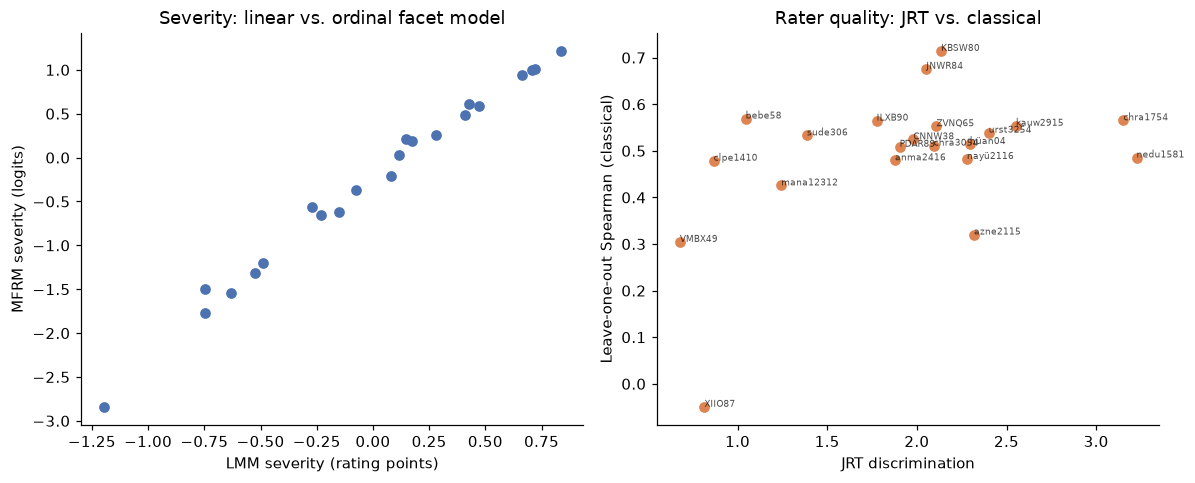

In [9]:
rater_cmp = raters["classical"][["rater_id", "n_ratings", "severity", "leave_one_out_spearman",
                                 "mean_pairwise_weighted_kappa"]].rename(columns={"severity": "severity_classical"})
rater_cmp = rater_cmp.merge(raters["lmm"][["rater_id", "severity", "drift_estimate", "drift_se"]]
                            .rename(columns={"severity": "severity_lmm"}), on="rater_id", how="left")
rater_cmp = rater_cmp.merge(raters["mfrm"][["rater_id", "severity", "infit_mnsq", "outfit_mnsq"]]
                            .rename(columns={"severity": "severity_mfrm"}), on="rater_id", how="left")
rater_cmp = rater_cmp.merge(raters["jrt"][["rater_id", "severity", "discrimination"]]
                            .rename(columns={"severity": "severity_jrt"}), on="rater_id", how="left")

severity_cols = ["severity_classical", "severity_lmm", "severity_mfrm", "severity_jrt"]
quality_cols = ["leave_one_out_spearman", "mean_pairwise_weighted_kappa", "infit_mnsq",
                "outfit_mnsq", "discrimination"]
severity_corr = rater_cmp[severity_cols].corr(method="spearman")
quality_corr = rater_cmp[quality_cols].corr(method="spearman")
save_table(severity_corr.reset_index().rename(columns={"index": "measure"}), "comparison_rater_severity_corr")
save_table(quality_corr.reset_index().rename(columns={"index": "measure"}), "comparison_rater_quality_corr")
print("Spearman correlations of rater severity:")
print(severity_corr.round(3))
print("\nSpearman correlations of rater-quality indicators:")
print(quality_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(rater_cmp["severity_lmm"], rater_cmp["severity_mfrm"], color="#4C72B0")
axes[0].set_xlabel("LMM severity (rating points)")
axes[0].set_ylabel("MFRM severity (logits)")
axes[0].set_title("Severity: linear vs. ordinal facet model")
axes[1].scatter(rater_cmp["discrimination"], rater_cmp["leave_one_out_spearman"], color="#DD8452")
axes[1].set_xlabel("JRT discrimination")
axes[1].set_ylabel("Leave-one-out Spearman (classical)")
axes[1].set_title("Rater quality: JRT vs. classical")
for _, r in rater_cmp.iterrows():
    axes[1].annotate(r["rater_id"], (r["discrimination"], r["leave_one_out_spearman"]), fontsize=6, alpha=0.7)
fig.tight_layout()
save_fig(fig, "fig_comparison_rater_parameters",
         "Rater parameters across approaches: severity from the linear vs. the ordinal facet "
         "model (left); JRT discrimination vs. classical leave-one-out consistency (right).")
plt.show()

## 5. Reliability across approaches

The approaches answer slightly different reliability questions, so the
numbers are not interchangeable:

- **Classical:** α is the agreement of single ratings. The Spearman–Brown
  value projects it to the mean of k ratings, treating rater severity as error.
- **LMM:** ICC(A,1)/Φ treats severity as error. ICC(C,1)/Eρ² does not, and is
  the reliability attainable for severity-adjusted scores.
- **MFRM/JRT:** separation, marginal and empirical reliability describe the
  latent scores the model actually estimates.

The empirical reliability $\operatorname{Var}(\hat s)/[\operatorname{Var}(\hat s)+\overline{\mathrm{PSD}^2}]$
is computed the same way for LMM, MFRM and JRT, and is the most direct
like-for-like comparison of the three model-based score sets.

In [10]:
def g(key, q):
    return diag[key].get(q, np.nan)

k_h = g("lmm", "k_harmonic")
reliability_summary = pd.DataFrame([
    {"approach": "classical", "coefficient": "Krippendorff alpha (ordinal), single rating", "value": g("classical", "alpha_ordinal")},
    {"approach": "classical", "coefficient": "Krippendorff alpha (interval), single rating", "value": g("classical", "alpha_interval")},
    {"approach": "classical", "coefficient": "Spearman-Brown (interval alpha), harmonic-mean k", "value": g("classical", "sb_interval_k_harmonic")},
    {"approach": "lmm", "coefficient": "ICC(A,1) = Phi(1)", "value": g("lmm", "icc_a1")},
    {"approach": "lmm", "coefficient": "ICC(C,1) = E rho^2(1)", "value": g("lmm", "icc_c1")},
    {"approach": "lmm", "coefficient": "Phi, harmonic-mean k", "value": g("lmm", "phi_k_harmonic")},
    {"approach": "lmm", "coefficient": "E rho^2, harmonic-mean k", "value": g("lmm", "erho2_k_harmonic")},
    {"approach": "lmm", "coefficient": "Empirical reliability of scores", "value": g("lmm", "empirical_reliability")},
    {"approach": "mfrm", "coefficient": "Action separation reliability", "value": g("mfrm", "action_separation_reliability")},
    {"approach": "mfrm", "coefficient": "Rater separation reliability (high = raters differ)", "value": g("mfrm", "rater_separation_reliability")},
    {"approach": "mfrm", "coefficient": "Empirical reliability of scores", "value": g("mfrm", "empirical_reliability")},
    {"approach": "jrt", "coefficient": "Marginal reliability, k = 1", "value": g("jrt", "marginal_reliability_k1")},
    {"approach": "jrt", "coefficient": "Marginal reliability, harmonic-mean k", "value": g("jrt", "marginal_reliability_k_harmonic")},
    {"approach": "jrt", "coefficient": "Empirical reliability of scores", "value": g("jrt", "empirical_reliability")},
])
save_table(reliability_summary, "comparison_reliability_summary")
print(f"Harmonic-mean number of ratings per action (largest component): {k_h:.2f}")
reliability_summary.round(3)

Table saved: results/tables/comparison_reliability_summary.csv (14 rows x 3 columns)
Harmonic-mean number of ratings per action (largest component): 1.73


,approach,coefficient,value
0,classical,"Krippendorff alpha (ordinal), single rating",0.391
1,classical,"Krippendorff alpha (interval), single rating",0.418
2,classical,"Spearman-Brown (interval alpha), harmonic-mean k",0.554
3,lmm,"ICC(A,1) = Phi(1)",0.421
4,lmm,"ICC(C,1) = E rho^2(1)",0.495
5,lmm,"Phi, harmonic-mean k",0.556
6,lmm,"E rho^2, harmonic-mean k",0.628
7,lmm,Empirical reliability of scores,0.644
8,mfrm,Action separation reliability,0.437
9,mfrm,Rater separation reliability (high = raters di...,0.870


## 6. Rater diagnostics and exploratory flags

Flags mark raters **exploratorily, not as "bad"**. Each criterion is weak on
its own, and they should be read together:
- very low category variation (≤ 2 categories used),
- very low connectivity (mean pairwise overlap < 5),
- low JRT discrimination (< 0.4),
- possible drift (|slope| > 2·SE),
- low leave-one-out consistency (Spearman < 0.1),
- MFRM misfit (infit or outfit outside 0.5–1.5),
- outside the largest connected component.

The response-style table comes from `01_data_overview.ipynb`.

In [11]:
DESC_PATH = RESULTS_TABLES / "rater_descriptive_statistics.csv"
if not DESC_PATH.exists():
    raise FileNotFoundError(f"{DESC_PATH.name} not found - run 01_data_overview.ipynb first.")
rater_desc = pd.read_csv(DESC_PATH, dtype={"rater_id": str})

# Connectivity per rater: number of rated actions and mean overlap with the raters they share actions with.
rater_ids_sorted = sorted(ratings_clean["rater_id"].unique())
r_idx = {r: i for i, r in enumerate(rater_ids_sorted)}
overlap = np.zeros((len(rater_ids_sorted),) * 2, dtype=int)
for raters_for_action in ratings_clean.groupby("action_id")["rater_id"].apply(list):
    idxs = sorted({r_idx[r] for r in raters_for_action})
    for a in range(len(idxs)):
        for b in range(a + 1, len(idxs)):
            overlap[idxs[a], idxs[b]] += 1
            overlap[idxs[b], idxs[a]] += 1
mean_pair_overlap = pd.Series(overlap.sum(axis=1) / np.maximum(1, (overlap > 0).sum(axis=1)),
                              index=rater_ids_sorted)

rater_diagnostics = rater_desc.merge(rater_cmp.drop(columns="n_ratings"), on="rater_id", how="left")
rater_diagnostics = rater_diagnostics.merge(
    raters["mfrm"][["rater_id", "severity_lower", "severity_upper"]].rename(columns={
        "severity_lower": "severity_mfrm_lower", "severity_upper": "severity_mfrm_upper"}),
    on="rater_id", how="left")
rater_diagnostics["network_component"] = np.where(
    rater_diagnostics["rater_id"].isin(largest_component_raters), 0, -1)
rater_diagnostics["network_degree"] = rater_diagnostics["rater_id"].map(
    ratings_clean.groupby("rater_id")["action_id"].nunique())
rater_diagnostics["mean_pair_overlap"] = rater_diagnostics["rater_id"].map(mean_pair_overlap)

def build_flags(row):
    flags = []
    if row.get("n_categories_used", 7) <= 2:
        flags.append("low_category_variation")
    if pd.notna(row.get("mean_pair_overlap")) and row["mean_pair_overlap"] < 5:
        flags.append("low_connectivity")
    if pd.notna(row.get("discrimination")) and row["discrimination"] < 0.4:
        flags.append("low_discrimination")
    if pd.notna(row.get("drift_estimate")) and pd.notna(row.get("drift_se")) and row["drift_se"] > 0:
        if abs(row["drift_estimate"]) > 2 * row["drift_se"]:
            flags.append("possible_drift")
    if pd.notna(row.get("leave_one_out_spearman")) and row["leave_one_out_spearman"] < 0.1:
        flags.append("low_loo_consistency")
    fits = [row.get("infit_mnsq"), row.get("outfit_mnsq")]
    if any(pd.notna(f) and not (0.5 <= f <= 1.5) for f in fits):
        flags.append("mfrm_misfit")
    if row.get("network_component", 0) != 0:
        flags.append("outside_largest_component")
    return ";".join(flags) if flags else "no_flag"

rater_diagnostics["diagnostic_flag"] = rater_diagnostics.apply(build_flags, axis=1)
n_flagged = (rater_diagnostics["diagnostic_flag"] != "no_flag").sum()
print(f"Raters with at least one exploratory flag: {n_flagged} of {len(rater_diagnostics)}")
print(rater_diagnostics["diagnostic_flag"].value_counts())

Raters with at least one exploratory flag: 11 of 22
diagnostic_flag
no_flag                                    11
possible_drift                              3
possible_drift;mfrm_misfit                  3
mfrm_misfit                                 2
low_category_variation;low_connectivity     1
low_connectivity;low_loo_consistency        1
low_connectivity;mfrm_misfit                1
Name: count, dtype: int64


## 7. Final result files: `action_scores.csv` and `rater_diagnostics.csv`

All score variants and rater parameters are combined into two files in
`data/processed/`. **Unavailable model values are `NaN`, not 0**, for example
for actions outside the largest component.

In [12]:
def score_flag(row):
    flags = []
    if row["n_ratings"] == 1:
        flags.append("single_rating")
    if row.get("connected_component", 0) != 0:
        flags.append("small_component")
    return ";".join(flags) if flags else "ok"

final_action_scores = score_comparison.copy()
final_action_scores["score_flag"] = final_action_scores.apply(score_flag, axis=1)
action_scores_out_cols = [
    "action_id", "n_ratings", "connected_component",
    "raw_mean", "raw_median", "raw_se", "rater_centered_mean",
    "lmm_score", "lmm_score_se", "lmm_score_lower", "lmm_score_upper",
    "mfrm_theta", "mfrm_theta_se", "mfrm_theta_lower", "mfrm_theta_upper", "mfrm_expected_rating",
    "jrt_theta", "jrt_theta_se", "jrt_theta_lower", "jrt_theta_upper",
    "score_flag",
]
final_action_scores_out = final_action_scores[action_scores_out_cols]
final_action_scores_out.to_csv(DATA_PROCESSED / "action_scores.csv", index=False)
print(f"action_scores.csv saved: {len(final_action_scores_out)} actions, "
      f"{final_action_scores_out.shape[1]} columns.")

rater_diagnostics_out_cols = [
    "rater_id", "n_ratings", "n_actions", "n_categories_used", "mean", "sd",
    "extreme_category_rate", "central_category_rate", "network_component", "network_degree",
    "mean_pair_overlap", "severity_classical", "severity_lmm", "severity_mfrm",
    "severity_mfrm_lower", "severity_mfrm_upper", "severity_jrt", "discrimination",
    "infit_mnsq", "outfit_mnsq", "leave_one_out_spearman", "mean_pairwise_weighted_kappa",
    "drift_estimate", "drift_se", "diagnostic_flag",
]
rater_diagnostics_out = (rater_diagnostics[[c for c in rater_diagnostics_out_cols if c in rater_diagnostics.columns]]
                         .rename(columns={"mean": "raw_mean", "sd": "raw_sd"}))
rater_diagnostics_out.to_csv(DATA_PROCESSED / "rater_diagnostics.csv", index=False)
print(f"rater_diagnostics.csv saved: {len(rater_diagnostics_out)} raters, "
      f"{rater_diagnostics_out.shape[1]} columns.")
final_action_scores_out.head()

action_scores.csv saved: 3669 actions, 21 columns.
rater_diagnostics.csv saved: 22 raters, 25 columns.


,action_id,n_ratings,connected_component,raw_mean,raw_median,raw_se,rater_centered_mean,lmm_score,lmm_score_se,lmm_score_lower,...,mfrm_theta,mfrm_theta_se,mfrm_theta_lower,mfrm_theta_upper,mfrm_expected_rating,jrt_theta,jrt_theta_se,jrt_theta_lower,jrt_theta_upper,score_flag
0,0005dd54-38ba-4d89-bec8-7fce98a9fa87,2,0,3.5,3.5,1.5,3.294148,3.315005,0.619677,2.114554,...,0.725785,1.079806,-1.464954,2.829259,3.427188,0.321649,0.802704,-1.274798,1.876844,ok
1,001329ae-1d80-48b8-a47d-4c39234a3273,2,0,3.5,3.5,1.5,3.837969,3.649877,0.599664,2.476345,...,1.485598,1.029363,-0.604382,3.477261,3.940706,0.744175,0.524151,-0.265368,1.749627,ok
2,00134704-d2c8-401f-a874-e3d6d52832b0,2,0,1.0,1.0,0.0,0.789951,1.675162,0.601621,0.480584,...,-2.734247,1.288645,-5.396072,-0.157179,1.557914,-1.294134,0.562738,-2.532946,-0.292495,ok
3,001c7a5d-cb4d-4e7c-adbb-52a716b2b265,2,0,2.0,2.0,0.0,1.954775,2.409673,0.617502,1.183361,...,-0.713562,1.047381,-2.749560,1.324974,2.522876,-0.408444,0.767729,-1.944115,1.061569,ok
4,004d5af3-5523-46ed-aace-6bf0eb43a7bc,2,0,1.5,1.5,0.5,1.961663,2.397893,0.607626,1.244069,...,-1.007856,1.161615,-3.343746,1.250205,2.357526,-0.551293,0.574851,-1.710586,0.526960,ok


### 7.1 Sample description

In [13]:
sample_description = pd.DataFrame([
    {"quantity": "Total number of ratings", "value": len(ratings_clean)},
    {"quantity": "Number of actions", "value": ratings_clean["action_id"].nunique()},
    {"quantity": "Number of raters", "value": n_raters},
    {"quantity": "Actions with 1 rating", "value": int((ratings_per_action == 1).sum())},
    {"quantity": "Actions with 2 ratings", "value": int((ratings_per_action == 2).sum())},
    {"quantity": "Actions with >=3 ratings", "value": int((ratings_per_action >= 3).sum())},
    {"quantity": "Harmonic-mean ratings per action (largest component)", "value": round(k_h, 2)},
    {"quantity": "Number of connected components", "value": n_components},
    {"quantity": "Actions in the largest component", "value": len(largest_component_actions)},
    {"quantity": "Krippendorff's alpha (ordinal)", "value": round(g("classical", "alpha_ordinal"), 3)},
    {"quantity": "sigma^2_action (LMM)", "value": round(g("lmm", "var_action"), 3)},
    {"quantity": "sigma^2_rater (LMM)", "value": round(g("lmm", "var_rater"), 3)},
    {"quantity": "sigma^2_residual (LMM)", "value": round(g("lmm", "var_resid"), 3)},
    {"quantity": "ICC(A,1) (LMM)", "value": round(g("lmm", "icc_a1"), 3)},
    {"quantity": "ICC(C,1) (LMM)", "value": round(g("lmm", "icc_c1"), 3)},
])
save_table(sample_description, "sample_description_summary")
sample_description

Table saved: results/tables/sample_description_summary.csv (15 rows x 2 columns)


,quantity,value
0,Total number of ratings,7844.000
1,Number of actions,3669.000
2,Number of raters,22.000
3,Actions with 1 rating,898.000
4,Actions with 2 ratings,2080.000
5,Actions with >=3 ratings,691.000
6,Harmonic-mean ratings per action (largest comp...,1.730
7,Number of connected components,1.000
8,Actions in the largest component,3669.000
9,Krippendorff's alpha (ordinal),0.391


### 7.2 Uncertainty intervals for selected action scores

For a sample of 40 actions, stratified by number of ratings: the 95% intervals
of the LMM fair score and the MFRM latent score, side by side.

Figure saved: fig_comparison_score_uncertainty.png / fig_comparison_score_uncertainty.svg


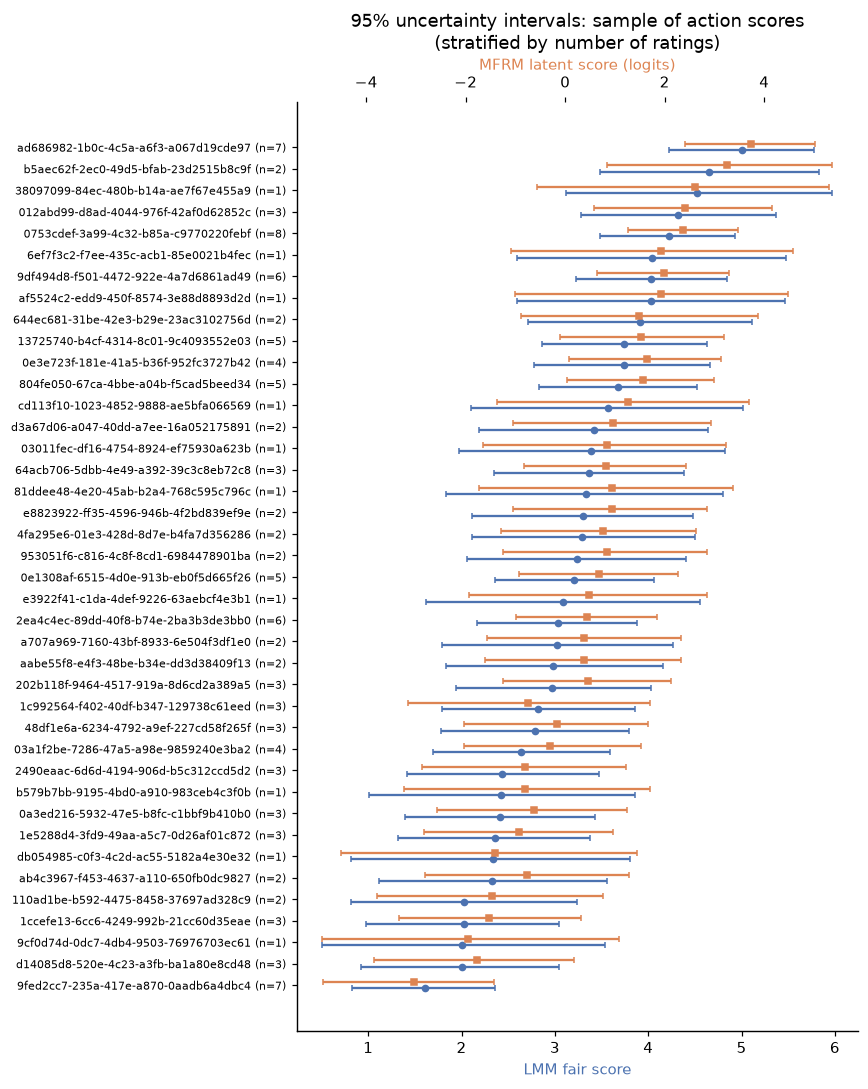

In [14]:
sample_for_plot = (
    final_action_scores.dropna(subset=["lmm_score", "mfrm_theta"])
    .groupby(final_action_scores["n_ratings"].clip(upper=4))
    .apply(lambda g: g.sample(min(10, len(g)), random_state=SEED), include_groups=False)
    .reset_index(drop=True)
    .sort_values("lmm_score")
)

fig, ax = plt.subplots(figsize=(8, 10))
y_pos = np.arange(len(sample_for_plot))
ax.errorbar(sample_for_plot["lmm_score"], y_pos - 0.15,
             xerr=[sample_for_plot["lmm_score"] - sample_for_plot["lmm_score_lower"],
                   sample_for_plot["lmm_score_upper"] - sample_for_plot["lmm_score"]],
             fmt="o", ms=4, color="#4C72B0", label="LMM fair score", capsize=2)
ax_ord = ax.twiny()
ax_ord.errorbar(sample_for_plot["mfrm_theta"], y_pos + 0.15,
                  xerr=[sample_for_plot["mfrm_theta"] - sample_for_plot["mfrm_theta_lower"],
                        sample_for_plot["mfrm_theta_upper"] - sample_for_plot["mfrm_theta"]],
                  fmt="s", ms=4, color="#DD8452", label="MFRM", capsize=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(sample_for_plot["action_id"] + " (n=" + sample_for_plot["n_ratings"].astype(str) + ")",
                     fontsize=7)
ax.set_xlabel("LMM fair score", color="#4C72B0")
ax_ord.set_xlabel("MFRM latent score (logits)", color="#DD8452")
ax.set_title("95% uncertainty intervals: sample of action scores\n"
              "(stratified by number of ratings)")
fig.tight_layout()
save_fig(fig, "fig_comparison_score_uncertainty",
         "95% uncertainty intervals for a sample of actions stratified by number of "
         "ratings: LMM fair score (blue, bottom) vs. MFRM latent score (orange, top).")
plt.show()

## 8. Automated, cautious interpretation

The following text is **automatically generated from the numbers
actually computed in this run** (no invented values). It does not
replace substantive discussion by the authors, but cautiously
summarizes the statistical findings. **Fixed thresholds are not
mechanically declared good/bad.**

In [15]:
pct_action, pct_rater, pct_resid = g("lmm", "pct_action"), g("lmm", "pct_rater"), g("lmm", "pct_resid")
icc_a1, icc_c1 = g("lmm", "icc_a1"), g("lmm", "icc_c1")
phi_kh, erho2_kh = g("lmm", "phi_k_harmonic"), g("lmm", "erho2_k_harmonic")
phi_k7 = g("lmm", "phi_k7")
n_single = int((ratings_per_action == 1).sum())
n_outside_largest = ratings_clean["action_id"].nunique() - len(largest_component_actions)
rater_effect_strength = "a noticeable" if pct_rater > 0.05 else "a relatively small"

if n_components == 1:
    component_note = "All rater severity estimates are therefore interpretable on a common scale."
else:
    component_note = (f"Rater severity estimates outside the largest component ({n_outside_largest} actions) "
                      "are not comparable to those inside it and have been flagged.")

elpd_diff, elpd_se = g("jrt", "elpd_diff_jrt_minus_facet"), g("jrt", "elpd_diff_se")
if np.isnan(elpd_diff):
    loo_note = "could not be computed in this run."
else:
    loo_note = (f"gave elpd_diff = {elpd_diff:.1f} (SE {elpd_se:.1f}; JRT minus equal-discrimination model, "
                "positive = JRT predicts better out of sample). Differences within about two standard "
                "errors favour the simpler model on parsimony grounds.")

rs = rank_shift_df.set_index("compared_with_raw_mean")
interpretation_text = f"""
The linear variance-component model (02b) attributes {pct_action:.1%} of the rating variance to
differences between actions, {pct_rater:.1%} to systematic differences between raters, and
{pct_resid:.1%} to residual variation (action x rater interaction, measurement error, other
unmodelled influences). This indicates {rater_effect_strength} rater-level effect. A single
rating has ICC(A,1) = {icc_a1:.2f} (severity counted as error) and ICC(C,1) = {icc_c1:.2f}
(severity removed).

With the current harmonic-mean number of ratings per action (k = {k_h:.2f}), the absolute
reliability of the raw action means is Phi = {phi_kh:.2f}. Removing rater severity would allow up
to E rho^2 = {erho2_kh:.2f}. Averaging seven ratings would raise Phi to {phi_k7:.2f}, which is
particularly relevant for the {n_single} actions that currently have a single rating.

Krippendorff's ordinal alpha is {g("classical", "alpha_ordinal"):.2f} (95% cluster-bootstrap CI
[{g("classical", "alpha_ordinal_ci_low"):.2f}, {g("classical", "alpha_ordinal_ci_high"):.2f}]),
describing agreement of single ratings across the incomplete design.

The empirical reliability of the model-based scores is {g("lmm", "empirical_reliability"):.2f} (LMM),
{g("mfrm", "empirical_reliability"):.2f} (ordinal facet model) and {g("jrt", "empirical_reliability"):.2f} (JRT).
Relative to the raw mean, the rank correlation is {rs.loc["lmm_score", "spearman"]:.2f} for the LMM
fair score, {rs.loc["mfrm_theta", "spearman"]:.2f} for the ordinal facet score and
{rs.loc["jrt_theta", "spearman"]:.2f} for the JRT score; {rs.loc["lmm_score", "top_10pct_overlap"]:.0%} of
the top-10% actions by raw mean remain in the top 10% after LMM rater correction.

The comparison between the ordinal facet model and the JRT extension with rater-specific
discrimination {loo_note}

The rater-action graph has {n_components} connected component(s). {component_note}

This summary refers to the present incompletely crossed design. Actions with a single rating
contribute to the model-based estimation but carry no within-action agreement information.
"""
print(interpretation_text)
with open(RESULTS_LOGS / "automated_interpretation.txt", "w") as f:
    f.write(interpretation_text)


The linear variance-component model (02b) attributes 42.0% of the rating variance to
differences between actions, 15.2% to systematic differences between raters, and
42.8% to residual variation (action x rater interaction, measurement error, other
unmodelled influences). This indicates a noticeable rater-level effect. A single
rating has ICC(A,1) = 0.42 (severity counted as error) and ICC(C,1) = 0.49
(severity removed).

With the current harmonic-mean number of ratings per action (k = 1.73), the absolute
reliability of the raw action means is Phi = 0.56. Removing rater severity would allow up
to E rho^2 = 0.63. Averaging seven ratings would raise Phi to 0.84, which is
particularly relevant for the 898 actions that currently have a single rating.

Krippendorff's ordinal alpha is 0.39 (95% cluster-bootstrap CI
[0.36, 0.42]),
describing agreement of single ratings across the incomplete design.

The empirical reliability of the model-based scores is 0.64 (LMM),
0.64 (ordinal facet model) 

## 9. Quality controls (automated checklist)

Checks are logged as a table rather than only as text.

In [16]:
qc_checks = []

def qc(name, condition, detail=""):
    qc_checks.append({"check": name, "passed": bool(condition), "detail": detail})

cleaning_log_path = RESULTS_TABLES / "cleaning_log.csv"
qc("IDs typed as strings", ratings_clean["action_id"].map(type).eq(str).all()
   and ratings_clean["rater_id"].map(type).eq(str).all())
qc("No duplicate rater-action pairs", not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any())
qc("All ratings in {1,...,7}", ratings_clean["rating_numeric"].between(1, 7).all())
qc("Connectivity checked and documented", n_components >= 1, f"{n_components} component(s)")
qc("LMM variance components non-negative",
   min(g("lmm", "var_action"), g("lmm", "var_rater"), g("lmm", "var_resid")) >= 0)
for key, label in [("lmm", "LMM"), ("mfrm", "Ordinal facet model"), ("jrt", "JRT model")]:
    qc(f"{label}: max R-hat < 1.01", g(key, "max_rhat") < 1.01, f"max R-hat = {g(key, 'max_rhat'):.4f}")
    qc(f"{label}: no divergences", g(key, "n_divergences") == 0, f"{g(key, 'n_divergences'):.0f} divergences")
    qc(f"{label}: min bulk ESS >= 400", g(key, "min_ess_bulk") >= 400, f"min ESS = {g(key, 'min_ess_bulk'):.0f}")
qc("Ordinal facet model: thresholds ordered", g("mfrm", "thresholds_ordered") == 1)
qc("LOO comparison JRT vs. facet model computed", not np.isnan(g("jrt", "elpd_diff_jrt_minus_facet")))
qc("All action scores exported with n_ratings and uncertainty",
   {"n_ratings", "raw_se", "lmm_score_se", "mfrm_theta_lower", "jrt_theta_se"}.issubset(final_action_scores_out.columns))
qc("Unavailable model scores are NaN, not 0",
   final_action_scores_out.loc[final_action_scores_out["connected_component"] != 0,
                               ["lmm_score", "mfrm_theta", "jrt_theta"]].isna().all().all())
qc("All approaches used the same number of connected components",
   len({diag[k].get("n_components") for k in APPROACHES} | {n_components}) == 1)
qc("Cleaning log documented", cleaning_log_path.exists() and len(pd.read_csv(cleaning_log_path)) > 0)
qc("Session info logged for every notebook",
   all((RESULTS_LOGS / f"session_info_{k}.json").exists() for k in list(APPROACHES) + ["comparison"]))

qc_df = pd.DataFrame(qc_checks)
save_table(qc_df, "qc_checklist")
n_failed_qc = int((~qc_df["passed"]).sum())
print(qc_df.to_string(index=False))
print(f"\n{n_failed_qc} of {len(qc_df)} quality controls not passed.")
if n_failed_qc > 0:
    log_warning(f"{n_failed_qc} quality controls (see qc_checklist.csv) not passed.")

Table saved: results/tables/qc_checklist.csv (21 rows x 3 columns)
                                                      check  passed             detail
                                       IDs typed as strings    True                   
                            No duplicate rater-action pairs    True                   
                                   All ratings in {1,...,7}    True                   
                        Connectivity checked and documented    True     1 component(s)
                       LMM variance components non-negative    True                   
                                      LMM: max R-hat < 1.01    True max R-hat = 1.0050
                                        LMM: no divergences    True      0 divergences
                                   LMM: min bulk ESS >= 400    True      min ESS = 847
                      Ordinal facet model: max R-hat < 1.01    True max R-hat = 1.0045
                        Ordinal facet model: no divergences    

/tmp/ipykernel_178512/1063489835.py:68: UserWarning: 2 quality controls (see qc_checklist.csv) not passed.
  warnings.warn(msg)


### 9.1 Warnings collected across all notebooks

In [17]:
upstream_warnings = [pd.read_csv(p) for k in APPROACHES
                     if (p := RESULTS_TABLES / f"warnings_log_{k}.csv").exists()
                     and p.stat().st_size > 0]
all_warnings = pd.concat(upstream_warnings + [pd.DataFrame(WARNINGS_LOG)], ignore_index=True)
save_table(all_warnings, "warnings_log")
print(f"{len(all_warnings)} warnings in total (see results/tables/warnings_log.csv).")
for _, w in all_warnings.iterrows():
    print(f"  [{w['notebook']}] {w['message']}")

Table saved: results/tables/warnings_log.csv (3 rows x 3 columns)
3 warnings in total (see results/tables/warnings_log.csv).
  [classical] Krippendorff's alpha values from different subsets (e.g. >=2 vs. >=3 ratings) are not directly comparable due to differing action heterogeneity.
  [jrt] Max R-hat = 1.0166 >= 1.01 for the JRT model.
  [comparison] 2 quality controls (see qc_checklist.csv) not passed.


## 10. Limitations and design implications

**Limitations**

1. **The residual covers several sources.** Most rater–action cells contain
   one rating, so the action × rater interaction cannot be separated from
   measurement error. The reliability coefficients are variance-component
   approximations, not a complete G-theory decomposition.
2. **The JRT model has shared thresholds.** Rater-specific thresholds were not
   estimated, for connectivity and compute-time reasons. See the R notebook
   for the `jrt` package fit.
3. **The cross-validation is simplified.** The rating-level CV in `02b` uses
   fast approximate predictors instead of refitting the model per fold.
4. **Scales differ between approaches.** The LMM score is on the 1–7 scale,
   MFRM θ in logits, and JRT θ on an N(0, 1) scale. Compare ranks or
   correlations, not raw values.
5. **Separate components.** If the rater–action graph has more than one
   component, rater severities are not comparable across components.

**Recommendations for future rating assignment**

1. **More ratings per action.** The D-studies in `02a` (Spearman–Brown),
   `02b` (Φ/Eρ²) and `02d` (marginal reliability) quantify the gain from each
   additional rating.
2. **Minimum overlap between raters.** Aim for at least 15–20 shared actions
   per rater with at least one well-connected "bridge" rater (see
   `01_data_overview.ipynb`).
3. **Anchor actions.** A small set of actions rated by (nearly) all raters
   stabilizes severity estimates and enables rater-specific thresholds.
4. **Balanced assignment.** Avoid confounding raters with action type or
   match (see the assignment check in `01_data_overview.ipynb`).
5. **Repeated anchors over time** make drift estimates more robust.
6. **Calibration sessions** for raters with low discrimination, misfit, or
   restricted category use.
7. **Separate training from final rating**, to keep learning effects out of
   the final data.